# Using The TiRex-2 Time Series Model for Predicting Weather Data in Austria

In this notebook we explore how well the TiRex-2 time series foundation model can predict weather data in Austria, in which scenarios it fails, and whether the model's multivariate capabilities can improve its predictions. We will focus mostly on temperature prediction (T2M - temperature two meters above ground).

## Dataset

The dataset is from the free and open [GeoSphere Austria Data Hub](https://data.hub.geosphere.at) (CC BY 4.0). We downloaded hourly time series data between 2025-10-01 an 2026-10-01 from 3363 data stations all across Austria. The weather features include `T2M` 2 m temperature, `RH2M` relative humidity, `TD2M` dew point,
`UU`/`VV` wind components, `P0` mean sea level pressure, `GL` global radiation, `RR` precipitation, and the derived `wind_speed`, `wind_dir` features.

In [1]:
# Imports
%matplotlib ipympl

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import ipywidgets as widgets
from IPython.display import display, clear_output

from tirex2 import ForecastModel, TimeseriesType, load_model

In [2]:
# Load the model
ckpt = "NX-AI/TiRex-2"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading checkpoint '{ckpt}' on device '{device}'")

model: ForecastModel = load_model(ckpt, device=device)
quantile_levels = np.asarray(model.quantiles.detach().cpu().numpy(), dtype=float)
print("Native quantiles:", np.round(quantile_levels, 3).tolist())
print("Maximum supported prediction length:", model.future_len)

Loading checkpoint 'NX-AI/TiRex-2' on device 'cpu'


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Native quantiles: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
Maximum supported prediction length: 320


## Initial Univariate Temperature Predictions

We explore some random locations at random time stamps and use a context (history) of 28 days (672 hourly data points) as input to TiRex and let TiRex predict the next 24 hours. This is well below TiRex's limit of 2048 step context (that would be 85 days for our dataset) and 320 (~ 13 days) step maximum prediction length. We plot this and print the mean absolute error (MAE).

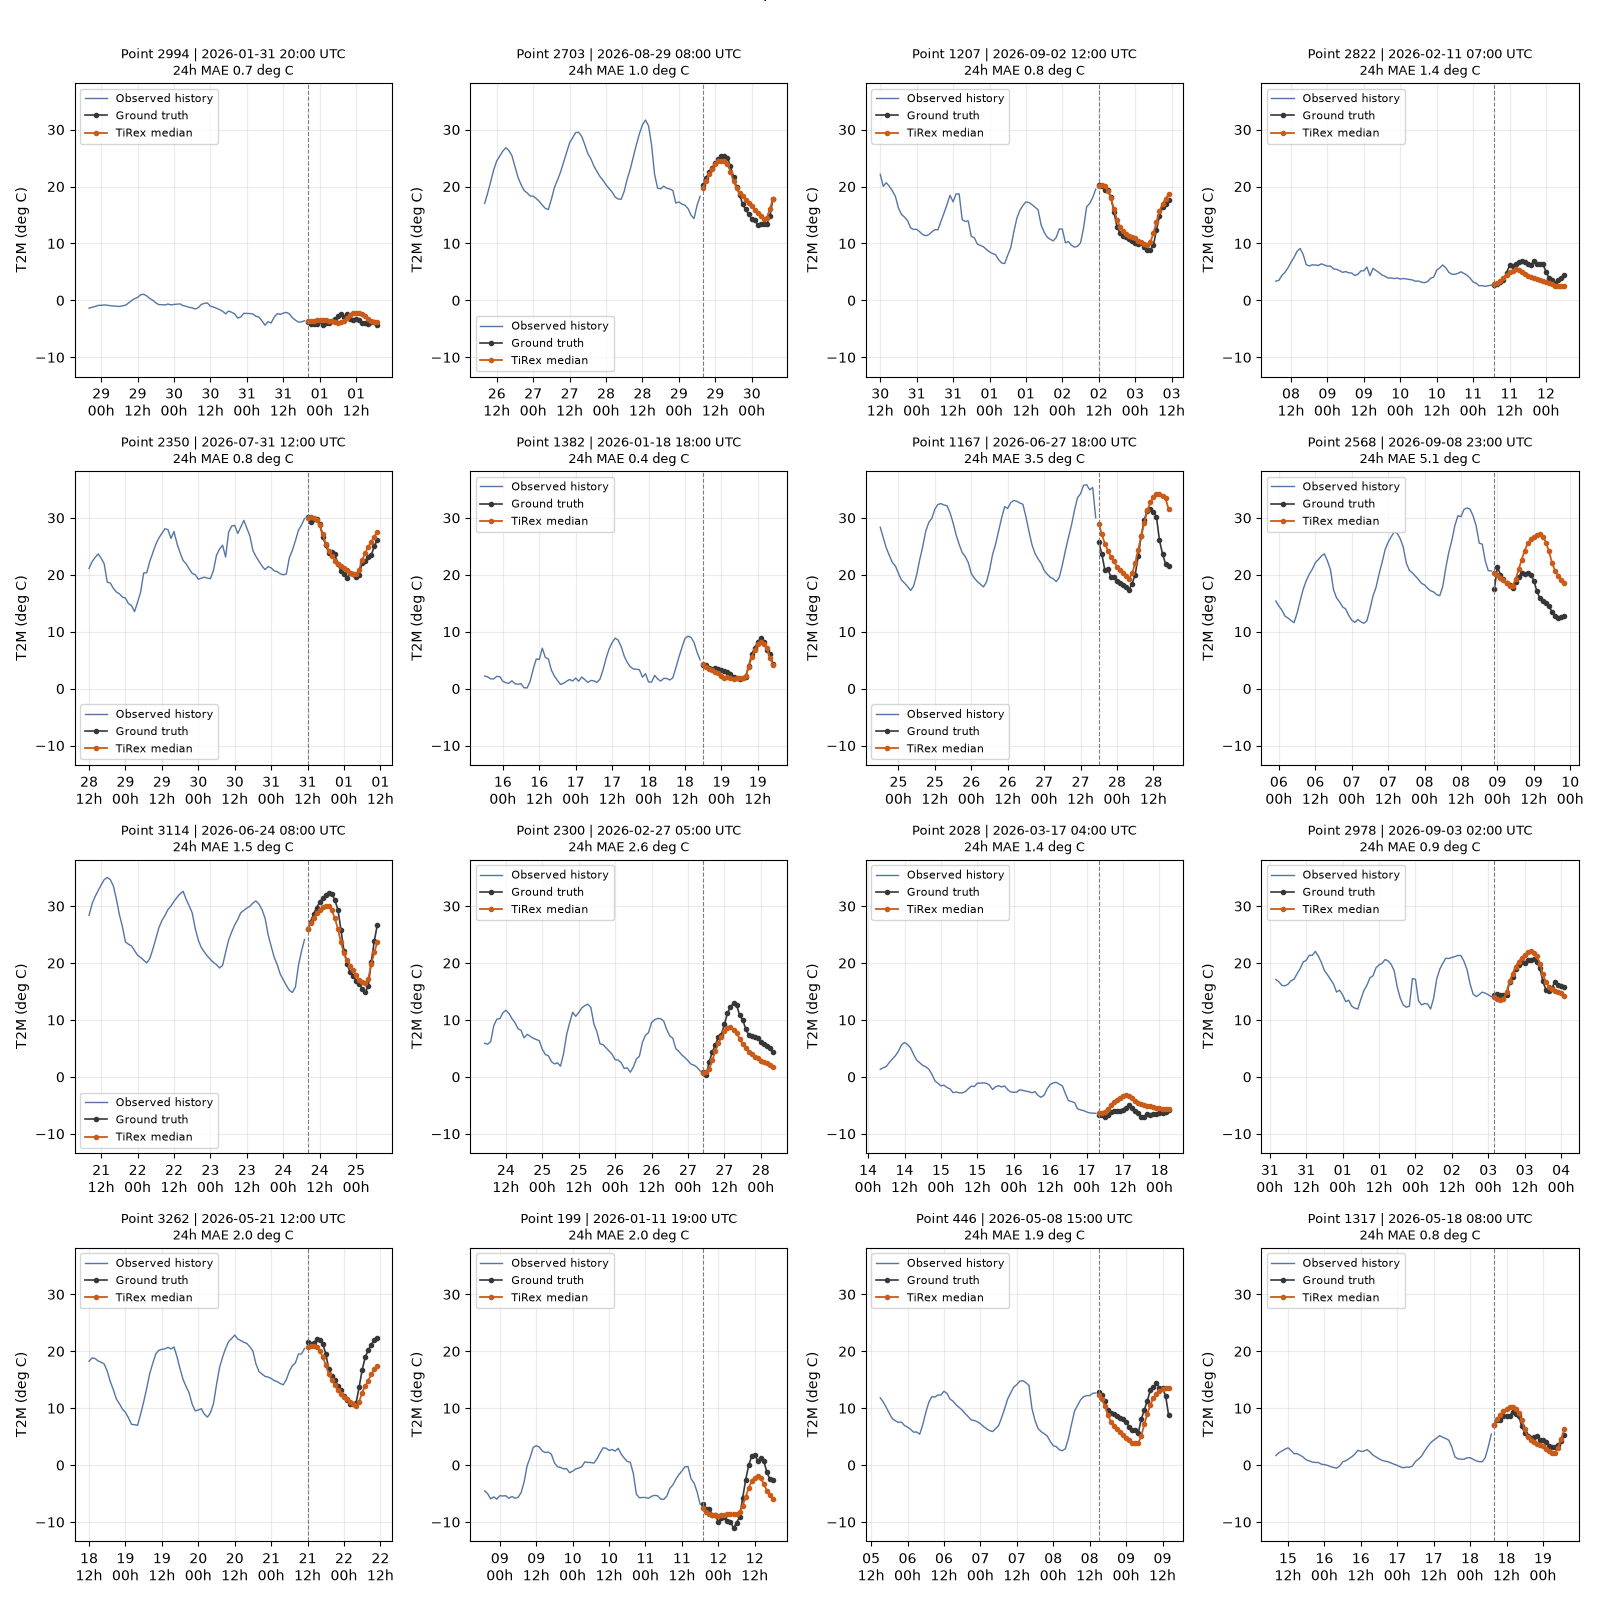

In [3]:
seed = 101
n_cases = 16
context_h = 672
horizon_h = 24
history_h = 72
max_context = 2048  # Maximum context length

rng = np.random.default_rng(seed)
data_path = "../data/austria_5km/grid_long.parquet"
points_path = "../data/austria_5km/points_with_labels.csv"

point_ids = np.sort(pd.read_csv(points_path, usecols=["point_id"])["point_id"].dropna().unique())
n_candidates = min(len(point_ids), n_cases * 4)
candidate_ids = rng.choice(point_ids, size=n_candidates, replace=False)
frame = pd.read_parquet(
    data_path, columns=["point_id", "time", "T2M"],
    filters=[("point_id", "in", candidate_ids.tolist())],
).sort_values(["point_id", "time"])

cases = []
groups = {int(point_id): group for point_id, group in frame.groupby("point_id", sort=False)}
for pid in candidate_ids:
    pid = int(pid)
    group = groups.get(pid)
    if group is None:
        continue
    series = (
        group.groupby("time")["T2M"].mean().sort_index().astype(float)
        .asfreq("1h").interpolate(limit=3, limit_area="inside")
    )
    values = series.to_numpy(dtype=np.float32)
    missing = (~np.isfinite(values)).astype(np.int64)
    missing_prefix = np.r_[0, np.cumsum(missing)]
    starts = np.arange(max_context, len(values) - horizon_h + 1)
    if len(starts) == 0:
        continue
    ok_history = (missing_prefix[starts] - missing_prefix[starts - max_context]) == 0
    ok_truth = (missing_prefix[starts + horizon_h] - missing_prefix[starts]) == 0
    valid_starts = starts[ok_history & ok_truth]
    if len(valid_starts):
        start = int(rng.choice(valid_starts))
        cases.append((int(pid), series, values, start))
    if len(cases) == n_cases:
        break

if len(cases) < n_cases:
    raise ValueError(f"Found only {len(cases)} locations with complete {max_context}-hour history and {horizon_h}-hour truth windows; need {n_cases}.")

requests = []
for _, _, values, start in cases:
    tensor = torch.from_numpy(
        values[start - context_h:start].copy()[None, :]
    )
    requests.append(TimeseriesType(target=tensor, past_covariates=None, future_covariates=None))
outputs = model.forecast(
    requests, prediction_length=horizon_h, output_type="numpy"
)
median_idx = int(np.argmin(np.abs(quantile_levels - 0.5)))

fig, axes = plt.subplots(4, 4, figsize=(16, 16), sharey=True, squeeze=False)
for i, (pid, series, values, start) in enumerate(cases):
    ax = axes.flat[i]
    times = pd.DatetimeIndex(series.index)
    left = max(0, start - history_h)
    past = np.arange(left, start)
    future = np.arange(start, start + horizon_h)
    forecast = np.asarray(outputs[i][0], dtype=float)[median_idx]
    truth = values[future]
    start_time = pd.Timestamp(times[start])
    mae = float(np.mean(np.abs(forecast - truth)))

    ax.plot(times[past], values[past], color="#5575a4", lw=1.0, label="Observed history")
    ax.plot(times[future], truth, color="#373737", lw=1.2, marker=".", label="Ground truth")
    ax.plot(times[future], forecast, color="#ca5b18", lw=1.3, marker=".", label="TiRex median")
    ax.axvline(start_time, color="#7c7c7c", ls="--", lw=0.8)
    ax.set_title(f"Point {pid} | {start_time:%Y-%m-%d %H:%M} UTC\n24h MAE {mae:.1f} deg C", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d\n%Hh"))
    ax.grid(alpha=0.25)
    ax.set_ylabel("T2M (deg C)")
    ax.tick_params(axis="y", labelleft=True)
    ax.legend(fontsize=8, loc="best")
fig.suptitle(f"Random TiRex-2 temperature forecasts (seed {seed})", y=1.01)
fig.tight_layout()

### Interpretation

We can see that TiRex does quite well in predicting the temperature given the previous temperature data from that station.

However, we can also see that there are cases (e.g. location 2568 on September 9th, 2nd row last column above), where the model was quite far off. The true data shows that there was a "surprising" drop in temperature which the model did not anticipate.

We will further investigate such scenarios to find out how the model behaves in those harder to predict scenarios (i.e. cold drops).

## Cold Drop Detection And Investigation

We find cold drops events in our dataset by finding all occasions where the temperature at time point `t0` was at least 8 degrees Celsius cooler than exactly 24 hours before. Then, we plot the model's behavior for some of those events.

First, we show some example cold drops frome station 2798 (in Vienna) and then see how TiRex performs.

In [15]:
# Cold drop detection function. At least 8 C colder than 24 hours before.
def find_cold_drops(t2m, threshold_c=8.0, gap_hours=6):
    """
    gap_hours exists in order to not count the same cold drop multiple times.
    To count a cold drop it must be at least gap_hours away from another cold drop.
    """
    hourly = t2m.groupby(level=0).mean().sort_index().asfreq("1h")
    change_24h = hourly - hourly.shift(24)
    hits = change_24h[change_24h <= -threshold_c].dropna()
    if hits.empty:
        return pd.DataFrame(columns=["time", "change_24h_c"])
    groups = hits.index.to_series().diff().gt(pd.Timedelta(hours=gap_hours)).cumsum()
    events = [{"time": values.idxmin(), "change_24h_c": values.min()}
              for _, values in hits.groupby(groups.to_numpy())]
    return pd.DataFrame(events).sort_values("change_24h_c").reset_index(drop=True)

Found 27 cold-drop events at location 2798. Plotting the 8 largest cold drops.
Cold drop 1 of -14.7 deg C at 2026-03-26 13:00. 24h MAE 5.93 deg C. Cold-drop delta (prediction - truth) 11.79 deg C
Cold drop 2 of -14.6 deg C at 2026-09-10 11:00. 24h MAE 2.41 deg C. Cold-drop delta (prediction - truth) 5.67 deg C
Cold drop 3 of -14.1 deg C at 2026-07-01 16:00. 24h MAE 4.47 deg C. Cold-drop delta (prediction - truth) 13.37 deg C
Cold drop 4 of -13.1 deg C at 2026-05-12 11:00. 24h MAE 3.76 deg C. Cold-drop delta (prediction - truth) 6.12 deg C
Cold drop 5 of -11.9 deg C at 2026-07-17 14:00. 24h MAE 3.41 deg C. Cold-drop delta (prediction - truth) 11.95 deg C
Cold drop 6 of -10.9 deg C at 2026-04-07 01:00. 24h MAE 1.42 deg C. Cold-drop delta (prediction - truth) 4.24 deg C
Cold drop 7 of -10.5 deg C at 2026-09-17 14:00. 24h MAE 5.09 deg C. Cold-drop delta (prediction - truth) 8.90 deg C
Cold drop 8 of -10.5 deg C at 2026-04-10 14:00. 24h MAE 4.69 deg C. Cold-drop delta (prediction - truth) 1

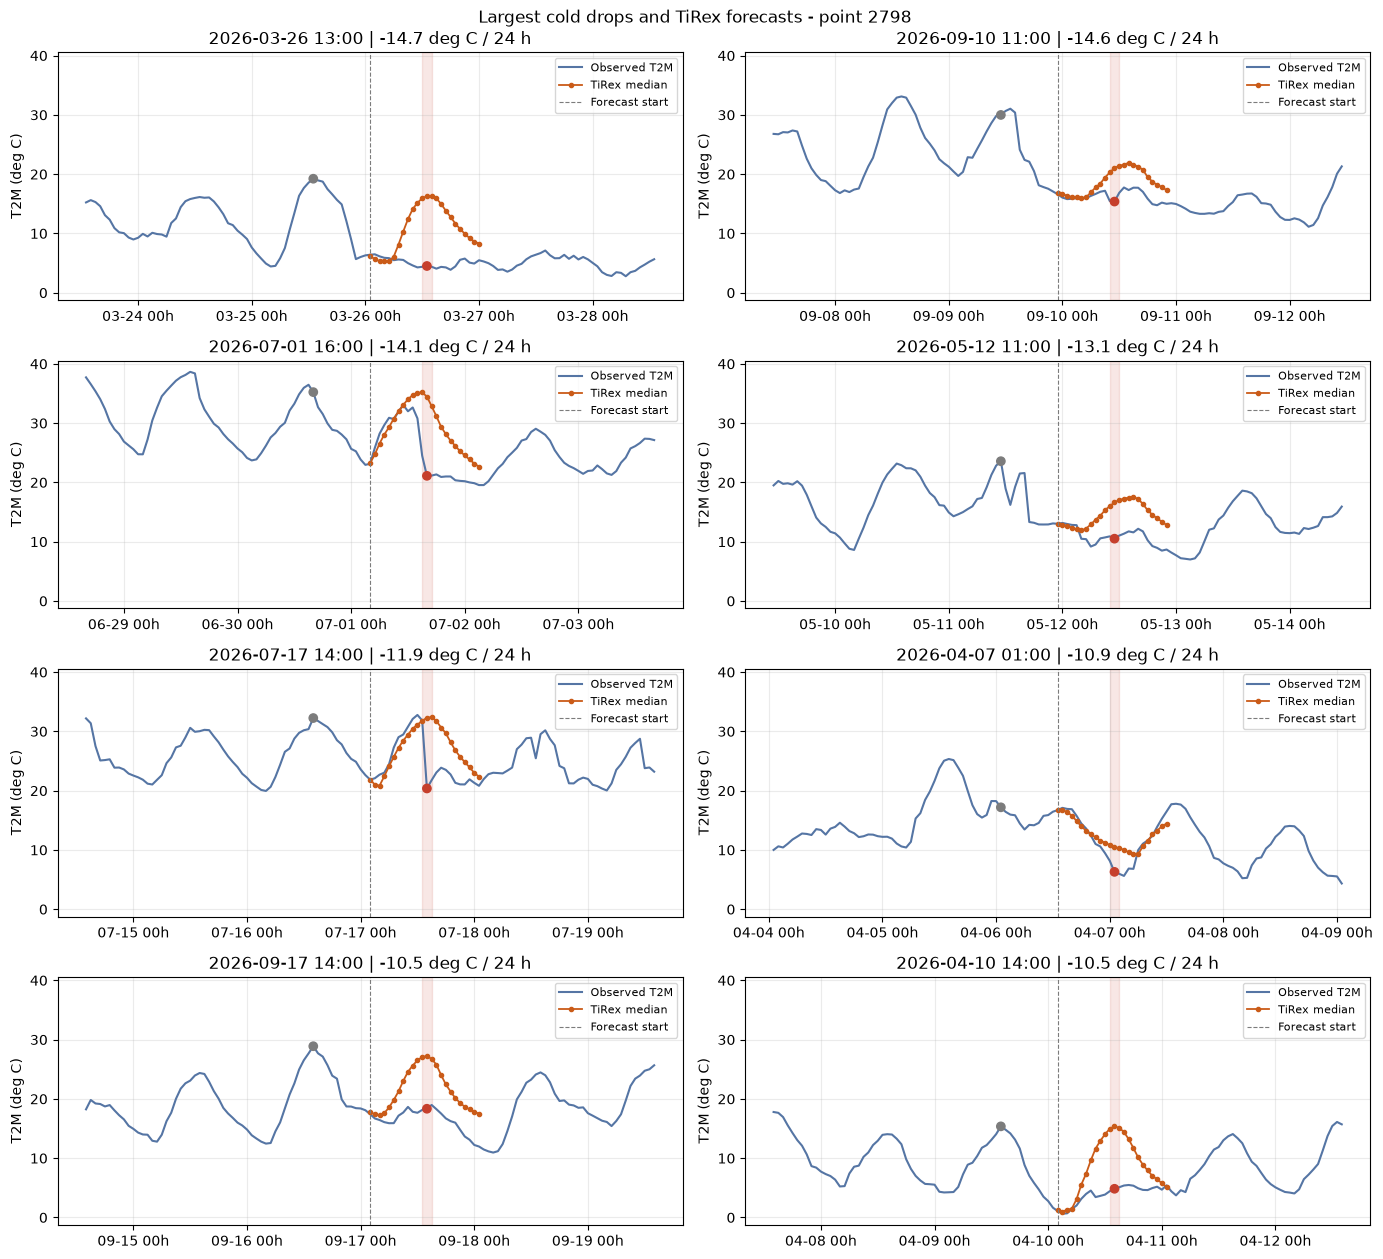

In [22]:
# Cold drop plotting and TiRex performance for example station 2798.
point_id = 2798
weather = pd.read_parquet(
    "../data/austria_5km/grid_long.parquet",
    columns=["point_id", "time", "T2M"],
    filters=[("point_id", "=", point_id)],
).sort_values("time")
t2m = (weather.set_index("time")["T2M"].astype(float)
       .groupby(level=0).mean().sort_index().asfreq("1h"))
drops = find_cold_drops(t2m)
top = drops.head(8)

print(f"Found {len(drops)} cold-drop events at location {point_id}. Plotting the {len(top)} largest cold drops.")
if top.empty:
    print("No 24-hour drops of at least 8 deg C found for this location.")
else:
    i = 0
    ncols = 2
    nrows = (len(top) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows), squeeze=False, sharey=True)
    for ax, event in zip(axes.flat, top.itertuples(index=False)):
        i += 1
        when = event.time
        start = when - pd.Timedelta(hours=12)
        past = t2m.loc[start - pd.Timedelta(hours=672):start - pd.Timedelta(hours=1)]
        fc = model.forecast(
            [TimeseriesType(target=torch.from_numpy(past.to_numpy(dtype=np.float32)[None, :]),
                            past_covariates=None, future_covariates=None)],
            prediction_length=24, output_type="numpy",
        )
        med = np.asarray(fc[0][0], dtype=float)[int(np.argmin(np.abs(quantile_levels - 0.5)))]
        win = t2m.loc[when - pd.Timedelta(hours=72):when + pd.Timedelta(hours=48)]
        truth = t2m.loc[start:start + pd.Timedelta(hours=23)]
        mae = np.mean(np.abs(med - truth.to_numpy()))
        delta = med[12] - t2m.loc[when]
        print(f"Cold drop {i} of {event.change_24h_c:.1f} deg C at {event.time:%Y-%m-%d %H:%M}. 24h MAE {mae:.2f} deg C. Cold-drop delta (prediction - truth) {delta:.2f} deg C")
        ref = when - pd.Timedelta(hours=24)
        ax.plot(win.index, win.values, color="#5575a4", lw=1.5, label="Observed T2M")
        ax.plot(truth.index, med, color="#ca5b18", lw=1.3, marker=".", label="TiRex median")
        ax.scatter([ref, when], t2m.reindex([ref, when]),
                   color=["#7c7c7c", "#c63f2c"], zorder=3)
        ax.axvline(start, color="#7c7c7c", ls="--", lw=0.8, label="Forecast start")
        ax.axvspan(when - pd.Timedelta(hours=1), when + pd.Timedelta(hours=1), color="#c63f2c", alpha=0.12)
        ax.set_title(f"{when:%Y-%m-%d %H:%M} | {event.change_24h_c:.1f} deg C / 24 h")
        ax.set_ylabel("T2M (deg C)")
        ax.tick_params(axis="y", labelleft=True)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %Hh"))
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8, loc="best")
    for ax in axes.flat[len(top):]:
        ax.set_visible(False)
    fig.suptitle(f"Largest cold drops and TiRex forecasts - point {point_id}")
    fig.tight_layout()
    display(fig)
    plt.close(fig)

### Trying to Improve Cold Drop Prediction through Covariates

We see that TiRex-2 can predict "normal" temperature patterns quite well, but for a cold front event, just having the temperature data leading up to such an event does not seem to be enough for TiRex to predict such events.

#### Covariates of The Same Station

Since TiRex-2 supports multiple covariates as input data, as a first simple improvement we can try to add more features of the same station as covariates, e.g. atmospheric pressure, rain, humidity, wind speed, wind direction.

Found 27 cold-drop events at location 2798. Plotting the 8 largest cold drops.
Cold drop 1 of -14.7 deg C at 2026-03-26 13:00. 24h MAE 5.99 deg C. Cold-drop delta (prediction - truth) 11.99 deg C
Cold drop 2 of -14.6 deg C at 2026-09-10 11:00. 24h MAE 2.71 deg C. Cold-drop delta (prediction - truth) 6.30 deg C
Cold drop 3 of -14.1 deg C at 2026-07-01 16:00. 24h MAE 4.57 deg C. Cold-drop delta (prediction - truth) 13.54 deg C
Cold drop 4 of -13.1 deg C at 2026-05-12 11:00. 24h MAE 3.93 deg C. Cold-drop delta (prediction - truth) 6.49 deg C
Cold drop 5 of -11.9 deg C at 2026-07-17 14:00. 24h MAE 3.38 deg C. Cold-drop delta (prediction - truth) 11.88 deg C
Cold drop 6 of -10.9 deg C at 2026-04-07 01:00. 24h MAE 1.37 deg C. Cold-drop delta (prediction - truth) 3.96 deg C
Cold drop 7 of -10.5 deg C at 2026-09-17 14:00. 24h MAE 5.09 deg C. Cold-drop delta (prediction - truth) 8.95 deg C
Cold drop 8 of -10.5 deg C at 2026-04-10 14:00. 24h MAE 4.56 deg C. Cold-drop delta (prediction - truth) 1

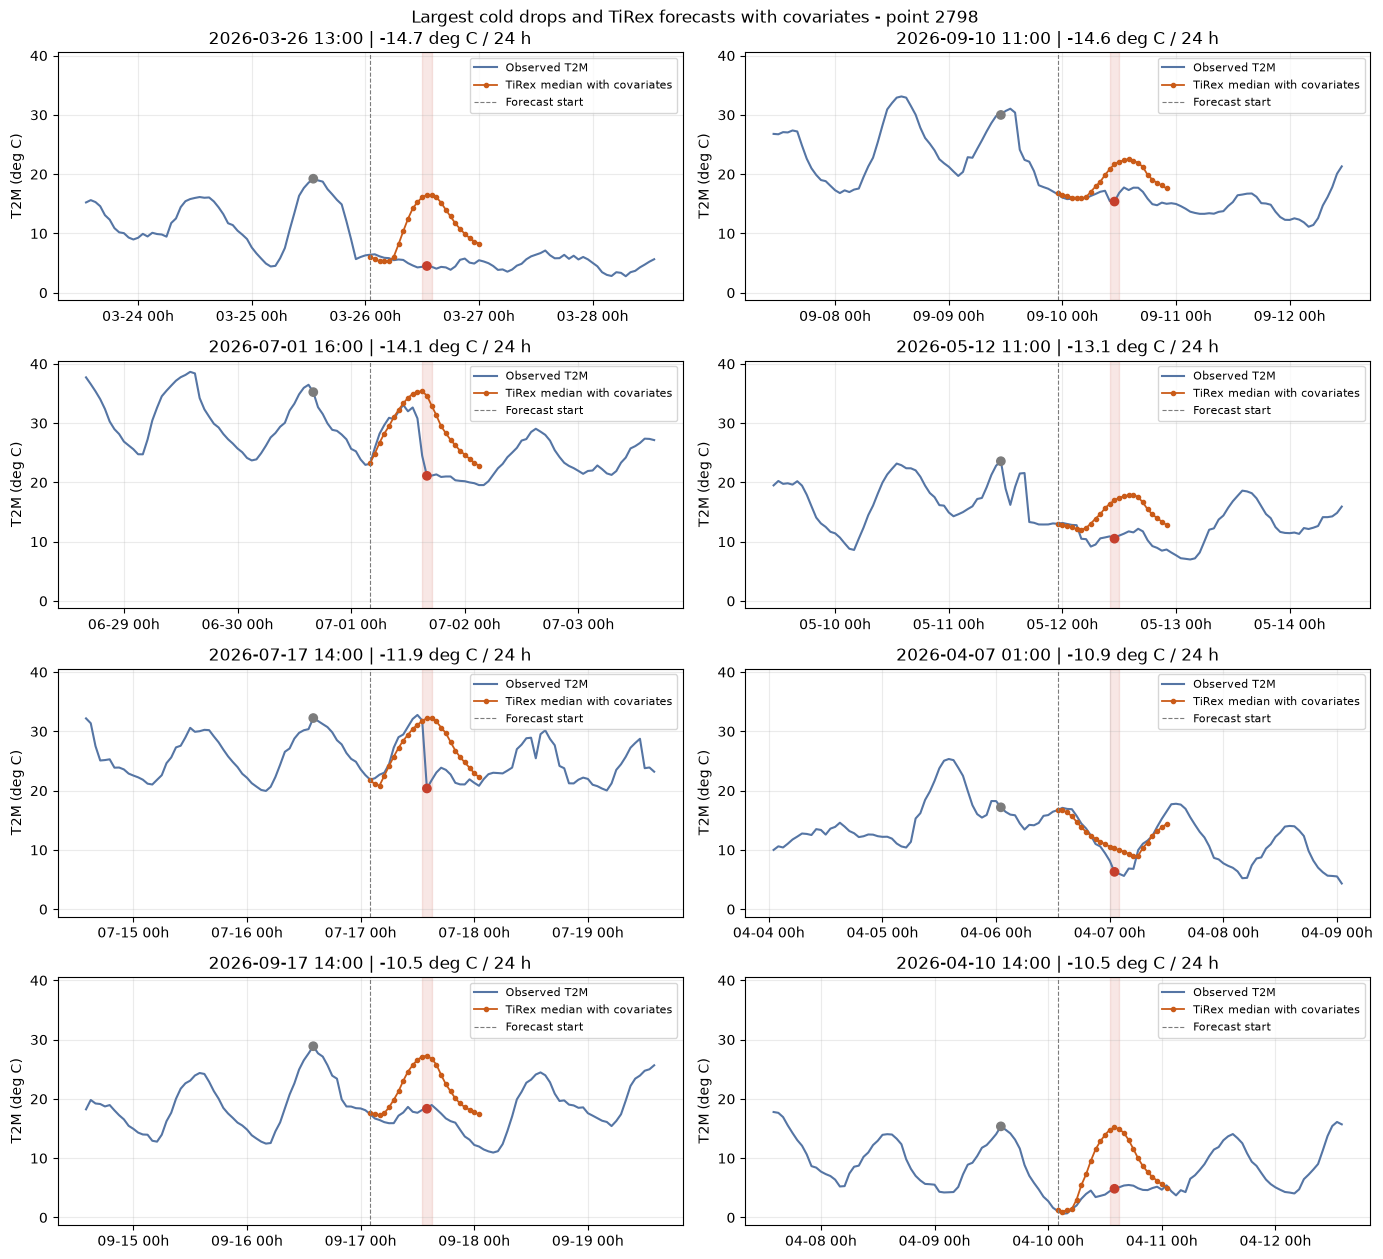

In [28]:
# Cold drop plotting and TiRex performance for example station 2798 with covariates of the same station.
point_id = 2798
covariate_columns = ["RH2M", "TD2M", "UU", "VV", "P0", "GL", "RR", "wind_speed", "wind_dir"]
weather = pd.read_parquet(
    "../data/austria_5km/grid_long.parquet",
    columns=["point_id", "time", "T2M", *covariate_columns],
    filters=[("point_id", "=", point_id)],
).sort_values("time")
hourly = weather.set_index("time").groupby(level=0).mean().sort_index().asfreq("1h")
t2m = hourly["T2M"].astype(float)
covariates = hourly[covariate_columns].interpolate(limit=3, limit_area="inside")
drops = find_cold_drops(t2m)
top = drops.head(8)

print(f"Found {len(drops)} cold-drop events at location {point_id}. Plotting the {len(top)} largest cold drops.")
if top.empty:
    print("No 24-hour drops of at least 8 deg C found for this location.")
else:
    i = 0
    ncols = 2
    nrows = (len(top) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows), squeeze=False, sharey=True)
    for ax, event in zip(axes.flat, top.itertuples(index=False)):
        i += 1
        when = event.time
        start = when - pd.Timedelta(hours=12)
        past = t2m.loc[start - pd.Timedelta(hours=672):start - pd.Timedelta(hours=1)]
        cov = covariates.loc[past.index].to_numpy(dtype=np.float32).T
        scale = cov.std(axis=1, keepdims=True)
        cov = (cov - cov.mean(axis=1, keepdims=True)) / np.where(scale > 1e-6, scale, 1.0)
        fc = model.forecast(
            [TimeseriesType(target=torch.from_numpy(past.to_numpy(dtype=np.float32)[None, :]),
                            past_covariates=torch.from_numpy(cov), future_covariates=None)],
            prediction_length=24, output_type="numpy",
        )
        med = np.asarray(fc[0][0], dtype=float)[int(np.argmin(np.abs(quantile_levels - 0.5)))]
        win = t2m.loc[when - pd.Timedelta(hours=72):when + pd.Timedelta(hours=48)]
        truth = t2m.loc[start:start + pd.Timedelta(hours=23)]
        mae = np.mean(np.abs(med - truth.to_numpy()))
        delta = med[12] - t2m.loc[when]
        print(f"Cold drop {i} of {event.change_24h_c:.1f} deg C at {event.time:%Y-%m-%d %H:%M}. 24h MAE {mae:.2f} deg C. Cold-drop delta (prediction - truth) {delta:.2f} deg C")
        ref = when - pd.Timedelta(hours=24)
        ax.plot(win.index, win.values, color="#5575a4", lw=1.5, label="Observed T2M")
        ax.plot(truth.index, med, color="#ca5b18", lw=1.3, marker=".", label="TiRex median with covariates")
        ax.scatter([ref, when], t2m.reindex([ref, when]),
                   color=["#7c7c7c", "#c63f2c"], zorder=3)
        ax.axvline(start, color="#7c7c7c", ls="--", lw=0.8, label="Forecast start")
        ax.axvspan(when - pd.Timedelta(hours=1), when + pd.Timedelta(hours=1), color="#c63f2c", alpha=0.12)
        ax.set_title(f"{when:%Y-%m-%d %H:%M} | {event.change_24h_c:.1f} deg C / 24 h")
        ax.set_ylabel("T2M (deg C)")
        ax.tick_params(axis="y", labelleft=True)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %Hh"))
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8, loc="best")
    for ax in axes.flat[len(top):]:
        ax.set_visible(False)
    fig.suptitle(f"Largest cold drops and TiRex forecasts with covariates - point {point_id}")
    fig.tight_layout()
    display(fig)
    plt.close(fig)

More features from the same station clearly do not improve the prediction at all.

#### Covariates of Other Stations (against Wind Direction)

The next hypothesis we want to test is whether adding data from other stations helps improve the prediction or not. For that, we first print the average wind directions of the station during those cold drop events and then add station data from the wind direction as covariates. The hypothesis being that cold drops should happen earlier at those stations and maybe that signal can help TiRex-2 predict the cold drop at the station.

In [29]:
# Print wind directions for cold drop events (re-uses point_id from above)
weather = pd.read_parquet(
    "../data/austria_5km/grid_long.parquet",
    columns=["point_id", "time", "T2M", "wind_dir", "wind_speed"],
    filters=[("point_id", "=", point_id)],
).sort_values("time")
t2m = (weather.set_index("time")["T2M"].astype(float)
       .groupby(level=0).mean().sort_index().asfreq("1h"))
drops = find_cold_drops(t2m)
top = drops.head(8).merge(
    weather[["time", "wind_dir", "wind_speed"]],
    on="time",
    how="left",
)

for i, event in enumerate(top.itertuples(index=False), start=1):
    print(f"Cold drop {i}: {event.change_24h_c:.1f} deg C at {event.time:%Y-%m-%d %H:%M}. Wind direction: {event.wind_dir:.0f} deg. Wind speed: {event.wind_speed:.1f}.")
radians = np.deg2rad(top["wind_dir"])
average_wind_dir = (np.rad2deg(np.arctan2(np.sin(radians).mean(), np.cos(radians).mean()))% 360)
print(f"Average wind direction across these events: {average_wind_dir:.0f} deg")

Cold drop 1: -14.7 deg C at 2026-03-26 13:00. Wind direction: 337 deg. Wind speed: 8.8.
Cold drop 2: -14.6 deg C at 2026-09-10 11:00. Wind direction: 284 deg. Wind speed: 1.9.
Cold drop 3: -14.1 deg C at 2026-07-01 16:00. Wind direction: 280 deg. Wind speed: 7.2.
Cold drop 4: -13.1 deg C at 2026-05-12 11:00. Wind direction: 287 deg. Wind speed: 5.3.
Cold drop 5: -11.9 deg C at 2026-07-17 14:00. Wind direction: 212 deg. Wind speed: 3.5.
Cold drop 6: -10.9 deg C at 2026-04-07 01:00. Wind direction: 294 deg. Wind speed: 2.1.
Cold drop 7: -10.5 deg C at 2026-09-17 14:00. Wind direction: 274 deg. Wind speed: 3.3.
Cold drop 8: -10.5 deg C at 2026-04-10 14:00. Wind direction: 199 deg. Wind speed: 2.0.
Average wind direction across these events: 273°


The average wind direction is almost exactly west (which matches our prior knowledge about weather in Austria). So will add data from stations in the west and see if that improves the forecast.

Found 27 cold-drop events at location 2798. Plotting the 8 largest cold drops.
Cold drop 1 of -14.7 deg C at 2026-03-26 13:00. 24h MAE 6.25 deg C. Cold-drop delta (prediction - truth) 12.57 deg C
Cold drop 2 of -14.6 deg C at 2026-09-10 11:00. 24h MAE 2.89 deg C. Cold-drop delta (prediction - truth) 6.35 deg C
Cold drop 3 of -14.1 deg C at 2026-07-01 16:00. 24h MAE 4.55 deg C. Cold-drop delta (prediction - truth) 13.15 deg C
Cold drop 4 of -13.1 deg C at 2026-05-12 11:00. 24h MAE 2.85 deg C. Cold-drop delta (prediction - truth) 4.36 deg C
Cold drop 5 of -11.9 deg C at 2026-07-17 14:00. 24h MAE 3.38 deg C. Cold-drop delta (prediction - truth) 12.20 deg C
Cold drop 6 of -10.9 deg C at 2026-04-07 01:00. 24h MAE 1.35 deg C. Cold-drop delta (prediction - truth) 3.93 deg C
Cold drop 7 of -10.5 deg C at 2026-09-17 14:00. 24h MAE 5.13 deg C. Cold-drop delta (prediction - truth) 9.09 deg C
Cold drop 8 of -10.5 deg C at 2026-04-10 14:00. 24h MAE 4.58 deg C. Cold-drop delta (prediction - truth) 1

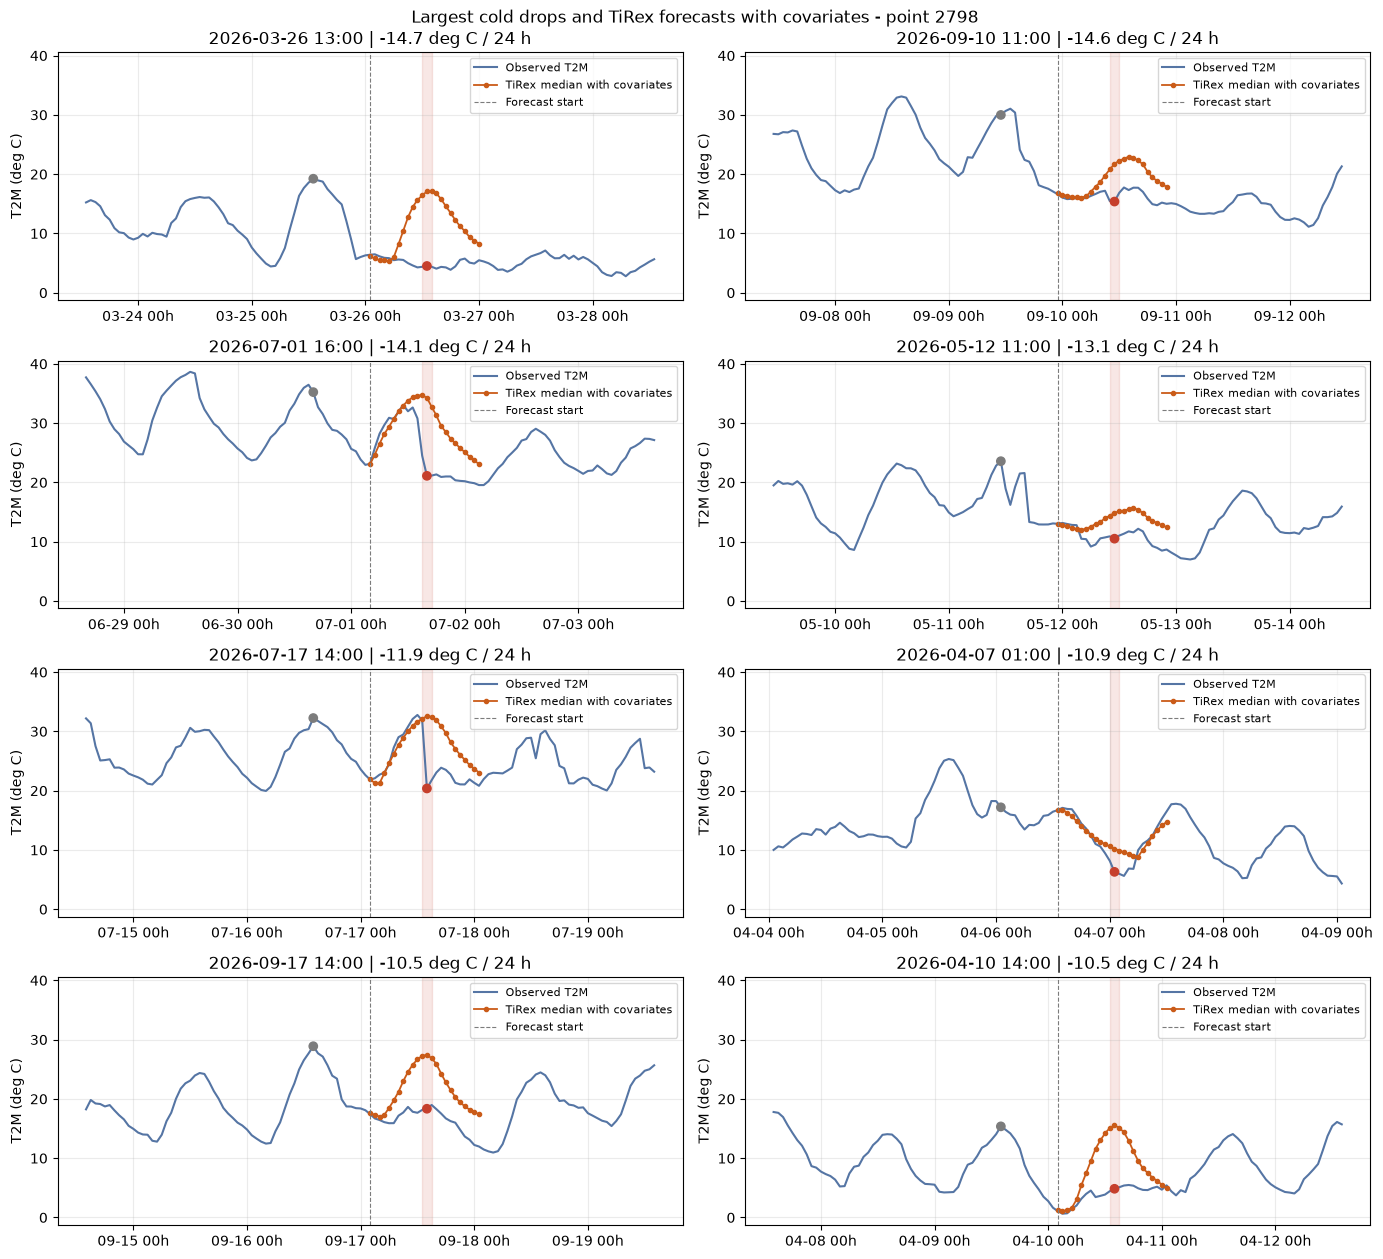

In [31]:
# Cold drop plotting and TiRex performance for example station 2798 with covariates of stations in the west.
point_id = 2798
covariate_point_ids = [2126, 2822, 2724]  # Salzburg, Linz, and Melk
covariate_columns = ["RH2M", "TD2M", "UU", "VV", "P0", "GL", "RR", "wind_speed", "wind_dir"]
weather = pd.read_parquet(
    "../data/austria_5km/grid_long.parquet",
    columns=["point_id", "time", "T2M", *covariate_columns],
    filters=[("point_id", "in", [point_id, *covariate_point_ids])],
).sort_values("time")
target = weather[weather["point_id"] == point_id]
hourly = target.set_index("time").groupby(level=0).mean().sort_index().asfreq("1h")
t2m = hourly["T2M"].astype(float)
covariates = (weather[weather["point_id"].isin(covariate_point_ids)]
              .pivot_table(index="time", columns="point_id", values=covariate_columns)
              .reindex(hourly.index).interpolate(limit=3, limit_area="inside"))
drops = find_cold_drops(t2m)
top = drops.head(8)

print(f"Found {len(drops)} cold-drop events at location {point_id}. Plotting the {len(top)} largest cold drops.")
if top.empty:
    print("No 24-hour drops of at least 8 deg C found for this location.")
else:
    i = 0
    ncols = 2
    nrows = (len(top) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows), squeeze=False, sharey=True)
    for ax, event in zip(axes.flat, top.itertuples(index=False)):
        i += 1
        when = event.time
        start = when - pd.Timedelta(hours=12)
        past = t2m.loc[start - pd.Timedelta(hours=2048):start - pd.Timedelta(hours=1)]
        cov = covariates.loc[past.index].to_numpy(dtype=np.float32).T
        scale = cov.std(axis=1, keepdims=True)
        cov = (cov - cov.mean(axis=1, keepdims=True)) / np.where(scale > 1e-6, scale, 1.0)
        fc = model.forecast(
            [TimeseriesType(target=torch.from_numpy(past.to_numpy(dtype=np.float32)[None, :]),
                            past_covariates=torch.from_numpy(cov), future_covariates=None)],
            prediction_length=24, output_type="numpy",
        )
        med = np.asarray(fc[0][0], dtype=float)[int(np.argmin(np.abs(quantile_levels - 0.5)))]
        win = t2m.loc[when - pd.Timedelta(hours=72):when + pd.Timedelta(hours=48)]
        truth = t2m.loc[start:start + pd.Timedelta(hours=23)]
        mae = np.mean(np.abs(med - truth.to_numpy()))
        delta = med[12] - t2m.loc[when]
        print(f"Cold drop {i} of {event.change_24h_c:.1f} deg C at {event.time:%Y-%m-%d %H:%M}. 24h MAE {mae:.2f} deg C. Cold-drop delta (prediction - truth) {delta:.2f} deg C")
        ref = when - pd.Timedelta(hours=24)
        ax.plot(win.index, win.values, color="#5575a4", lw=1.5, label="Observed T2M")
        ax.plot(truth.index, med, color="#ca5b18", lw=1.3, marker=".", label="TiRex median with covariates")
        ax.scatter([ref, when], t2m.reindex([ref, when]),
                   color=["#7c7c7c", "#c63f2c"], zorder=3)
        ax.axvline(start, color="#7c7c7c", ls="--", lw=0.8, label="Forecast start")
        ax.axvspan(when - pd.Timedelta(hours=1), when + pd.Timedelta(hours=1), color="#c63f2c", alpha=0.12)
        ax.set_title(f"{when:%Y-%m-%d %H:%M} | {event.change_24h_c:.1f} deg C / 24 h")
        ax.set_ylabel("T2M (deg C)")
        ax.tick_params(axis="y", labelleft=True)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %Hh"))
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8, loc="best")
    for ax in axes.flat[len(top):]:
        ax.set_visible(False)
    fig.suptitle(f"Largest cold drops and TiRex forecasts with covariates - point {point_id}")
    fig.tight_layout()
    display(fig)
    plt.close(fig)

Data of weather stations in the west did not improve TiRex's ability to predict cold drops. Why that might be the case is a potential question to investigate in Phase II.

## Bonus: Interactive Forecast Explorer

Wit the interactive exporer below, you can edit data points as you wish and see how TiRex's univariate prediction changes. This did not generate very useful insights for us, but is a fun interactive visualization.

In [37]:
# Default location 2798 is Vienna. Change this value to explore a different location.
point_id = 2798
context_hours = 672
horizon_hours = 24
visible_history_hours = 72

weather = pd.read_parquet(
    "../data/austria_5km/grid_long.parquet",
    columns=["point_id", "time", "T2M"],
    filters=[("point_id", "=", point_id)],
).sort_values("time")
weather = weather.set_index("time")["T2M"].astype(float).interpolate(limit=3)

original_t2m = weather.to_numpy(dtype=np.float32)
edited_t2m = original_t2m.copy()
time_index = pd.DatetimeIndex(pd.to_datetime(weather.index))

# A valid forecast start has a full 672-hour input and 24-hour evaluation window.
# A prefix sum lets us check all possible forecast starts efficiently, including the last
# forecast start whose truth window ends at the final row.
missing = (~np.isfinite(original_t2m)).astype(np.int64)
missing_prefix = np.r_[0, np.cumsum(missing)]
all_forecast_starts = np.arange(context_hours, len(original_t2m) - horizon_hours + 1)
complete_history = (missing_prefix[all_forecast_starts] - missing_prefix[all_forecast_starts - context_hours]) == 0
complete_truth = (missing_prefix[all_forecast_starts + horizon_hours] - missing_prefix[all_forecast_starts]) == 0
valid_forecast_starts = all_forecast_starts[complete_history & complete_truth]
if len(valid_forecast_starts) == 0:
    raise ValueError(f"No complete {context_hours}-hour history + {horizon_hours}-hour truth windows for point {point_id}")

forecast_start_slider = widgets.IntSlider(
    value=0, min=0, max=len(valid_forecast_starts) - 1, step=1,
    description="Forecast start", continuous_update=False,
    readout=False, layout=widgets.Layout(width="min(900px, 90%)"),
)
forecast_start_label = widgets.Label()
forecast_start_time_input = widgets.Text(
    description="Forecast start time (UTC)", placeholder="YYYY-MM-DD HH:MM",
    continuous_update=False, layout=widgets.Layout(width="230px"),
)
go_to_time_button = widgets.Button(description="Go to time", icon="search")
run_button = widgets.Button(description="Run forecast", button_style="primary", icon="play")
reset_button = widgets.Button(description="Reset edits", icon="undo")
status = widgets.HTML()
metrics_output = widgets.Output()

state = {"drag_index": None, "forecast_start": None}

In [38]:
def start_idx():
    return int(valid_forecast_starts[forecast_start_slider.value])

def sync_label(*_):
    start_time = pd.Timestamp(time_index[start_idx()])
    forecast_start_label.value = f"Forecast start (UTC): {start_time:%Y-%m-%d %H:%M}"
    forecast_start_time_input.value = start_time.strftime("%Y-%m-%d %H:%M")


def jump_time(_=None):
    time_text = forecast_start_time_input.value.strip()
    try:
        when = pd.Timestamp(pd.to_datetime(time_text, format="%Y-%m-%d %H:%M"))
        if time_index.tz is not None:
            when = when.tz_localize(time_index.tz)
    except (TypeError, ValueError):
        status.value = (
            "<span style='color:#a32'>Enter the forecast start as YYYY-MM-DD HH:MM, "
            "for example 2026-07-17 14:00.</span>"
        )
        return

    valid_times = time_index[valid_forecast_starts]
    found = np.flatnonzero(valid_times == when)
    if len(found) == 0:
        first_txt = pd.Timestamp(valid_times[0]).strftime("%Y-%m-%d %H:%M")
        last_txt = pd.Timestamp(valid_times[-1]).strftime("%Y-%m-%d %H:%M")
        status.value = (
            f"<span style='color:#a32'>That time is not a valid forecast start. "
            f"Available forecast starts run from {first_txt} UTC to {last_txt} UTC; the selected time must "
            f"have a complete history and 24-hour truth window.</span>"
        )
        return

    pos = int(found[0])
    if forecast_start_slider.value == pos:
        status.value = "<i>That forecast start is already selected.</i>"
    else:
        forecast_start_slider.value = pos


def redraw(show_fc=False):
    forecast_start = start_idx()
    lo = max(0, forecast_start - visible_history_hours)
    hist = np.arange(lo, forecast_start)
    fut = np.arange(forecast_start, forecast_start + horizon_hours)
    ax.clear()

    ax.plot(time_index[hist], original_t2m[hist], color="#5476a3", lw=1.6, label="Original history")
    ax.plot(time_index[hist], edited_t2m[hist], color="#de8031", lw=1.4, alpha=0.9, label="Edited history")
    dots = ax.scatter(
        time_index[hist], edited_t2m[hist], s=35, color="#de8031",
        edgecolor="#fbfbfb", linewidth=0.6, zorder=4, picker=True,
        label="Drag points to edit",
    )
    ax.plot(time_index[fut], original_t2m[fut], color="#363636", lw=1.5, marker=".", label="Observed future")
    ax.axvline(time_index[forecast_start], color="#7b7b7b", ls="--", lw=1, label="Forecast forecast_start")

    if show_fc and state["forecast_start"] == forecast_start:
        fc = state["forecast"]
        for key, color, label in (("original", "#295fa3", "Original-input forecast"),
                                  ("edited", "#c95c17", "Edited-input forecast")):
            pred = fc[key]
            ax.fill_between(time_index[fut], pred["q10"], pred["q90"], color=color, alpha=0.13)
            ax.plot(time_index[fut], pred["median"], color=color, lw=2, marker="o", ms=3, label=label)

    ax.set_title(f"T2M forecast exploration - point {point_id}")
    ax.set_ylabel("2 m temperature (deg C)")
    ax.set_xlim(time_index[lo], time_index[forecast_start + horizon_hours - 1])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
    ax.grid(True, alpha=0.25)
    ax.legend(ncol=2, loc="best", fontsize=9)
    fig.autofmt_xdate()
    fig.canvas.draw_idle()


def model_fc(series, forecast_start):
    past = series[forecast_start - context_hours:forecast_start]
    tensor = torch.from_numpy(past.astype(np.float32, copy=True)[None, :])
    ts = TimeseriesType(target=tensor, past_covariates=None, future_covariates=None)
    raw = model.forecast([ts], prediction_length=horizon_hours, output_type="numpy")
    qs = np.asarray(raw[0][0], dtype=float)  # (quantile, horizon)
    return {
        "q10": qs[int(np.argmin(np.abs(quantile_levels - 0.1)))],
        "median": qs[int(np.argmin(np.abs(quantile_levels - 0.5)))],
        "q90": qs[int(np.argmin(np.abs(quantile_levels - 0.9)))],
    }


def run_forecast(_=None):
    forecast_start = start_idx()
    status.value = "<i>Running TiRex-2 on original and edited histories...</i>"
    run_button.disabled = True
    reset_button.disabled = True
    try:
        orig_fc = model_fc(original_t2m, forecast_start)
        edit_fc = model_fc(edited_t2m, forecast_start)
        state["forecast"] = {"original": orig_fc, "edited": edit_fc}
        state["forecast_start"] = forecast_start
        truth = original_t2m[forecast_start:forecast_start + horizon_hours]
        steps = [1, 3, 6, 12, 24]
        table = []
        for key, title in (("original", "Original input"), ("edited", "Edited input")):
            med = state["forecast"][key]["median"]
            rec = {"Input": title, "24-hour MAE (deg C)": float(np.mean(np.abs(med - truth)))}
            rec.update({f"error at {lead}h (deg C)": float(abs(med[lead - 1] - truth[lead - 1])) for lead in steps})
            table.append(rec)
        with metrics_output:
            clear_output(wait=True)
            display(pd.DataFrame(table).set_index("Input").round(2))
        status.value = "<span style='color:#277c40'>Forecasts complete. Drag a point and run again to compare.</span>"
        redraw(show_fc=True)
    except Exception as exc:
        status.value = f"<span style='color:#a32'>Forecast failed: {type(exc).__name__}: {exc}</span>"
        raise
    finally:
        run_button.disabled = False
        reset_button.disabled = False


def reset_edits(_):
    edited_t2m[:] = original_t2m
    state["forecast_start"] = None
    with metrics_output:
        clear_output(wait=True)
    status.value = "<i>Edits reset. Recomputing forecasts from the original history...</i>"
    redraw(show_fc=False)
    run_forecast()


def grab_point(event):
    if event.inaxes is not ax or event.button != 1:
        return
    for artist in ax.collections:
        contains, details = artist.contains(event)
        if contains and len(details.get("ind", [])):
            start = max(0, start_idx() - visible_history_hours)
            state["drag_index"] = start + int(details["ind"][0])
            return


def drag_point(event):
    idx = state["drag_index"]
    if idx is None or event.inaxes is not ax or event.ydata is None:
        return
    edited_t2m[idx] = np.float32(event.ydata)
    if state["forecast_start"] == start_idx():
        state["forecast_start"] = None
        with metrics_output:
            clear_output(wait=True)
        status.value = "<i>History edited. Run a forecast to update the comparison.</i>"
    redraw(show_fc=False)


def release_point(_event):
    state["drag_index"] = None


def start_changed(change):
    if change["name"] != "value":
        return
    state["forecast_start"] = None
    with metrics_output:
        clear_output(wait=True)
    status.value = "<i>Forecast start changed. Run a forecast to compare this window.</i>"
    sync_label()
    redraw(show_fc=False)

/tmp/ipykernel_3253/949345663.py:4: DeprecationWarning: on_submit is deprecated. Instead, set the .continuous_update attribute to False and observe the value changing with: mywidget.observe(callback, 'value').
  forecast_start_time_input.on_submit(jump_time)


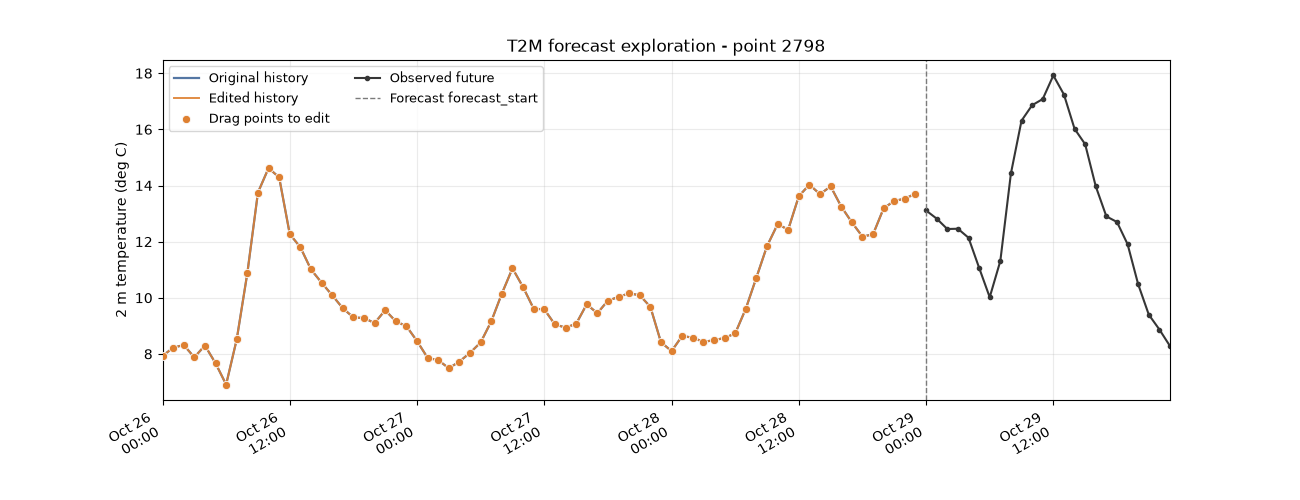

In [39]:
fig, ax = plt.subplots(figsize=(13, 5))

forecast_start_slider.observe(start_changed, names="value")
forecast_start_time_input.on_submit(jump_time)
go_to_time_button.on_click(jump_time)
run_button.on_click(run_forecast)
reset_button.on_click(reset_edits)
fig.canvas.mpl_connect("button_press_event", grab_point)
fig.canvas.mpl_connect("motion_notify_event", drag_point)
fig.canvas.mpl_connect("button_release_event", release_point)
sync_label()
redraw()
display(widgets.VBox([
    widgets.HBox([forecast_start_slider, forecast_start_label]),
    widgets.HBox([forecast_start_time_input, go_to_time_button]),
    widgets.HBox([run_button, reset_button]), status, metrics_output,
]))

## Bonus: 2D Time Curve

Each point represents the trailing 24 hours of one location's selected weather feature. PCA places similar daily patterns near one another, and the path connects window endpoints in chronological order. The color shows the feature value at each window's end. The principal component axes are pattern coordinates, not weather measurements.

In [40]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

# Slightly nudge the plasma palette so the scatter colours differ subtly.
plasma_shift = ListedColormap(
    np.clip(plt.get_cmap("plasma")(np.linspace(0, 1, 256))[:, :3] * 0.97 + 0.015, 0, 1)
)

curve_point_input = widgets.IntText(
    value=2798, description="Location ID", layout=widgets.Layout(width="220px"),
)
curve_feature_input = widgets.Dropdown(
    options=cov_features, value="T2M", description="Feature",
    layout=widgets.Layout(width="220px"),
)
curve_output = widgets.Output()


def draw_time_curve(*_):
    """Project trailing 24-hour windows and draw their chronological path."""
    with curve_output:
        clear_output(wait=True)
        try:
            feature = curve_feature_input.value
            table = pd.read_parquet(
                "../data/austria_5km/grid_long.parquet",
                columns=["point_id", "time", feature],
                filters=[("point_id", "=", int(curve_point_input.value))],
            )
            if table.empty:
                raise ValueError(f"No data found for location {curve_point_input.value}.")

            table["time"] = pd.to_datetime(table["time"])
            series = (table.set_index("time")[feature].astype(float)
                      .groupby(level=0).mean().sort_index())
            hourly_index = pd.date_range(series.index.min(), series.index.max(), freq="1h")
            values = series.reindex(hourly_index).to_numpy(dtype=np.float64)
            if len(values) < 24:
                raise ValueError("At least 24 hourly observations are needed to form a window.")

            windows = np.lib.stride_tricks.sliding_window_view(values, 24)
            window_ends = hourly_index[23:]
            complete = np.isfinite(windows).all(axis=1)
            windows = windows[complete]
            window_ends = window_ends[complete]
            if len(windows) < 2:
                raise ValueError("Fewer than two complete 24-hour windows are available.")

            coordinates = PCA(n_components=2).fit_transform(windows)
            end_values = windows[:, -1]

            fig, ax = plt.subplots(figsize=(9, 6))
            # Connect consecutive retained windows in chronological order.
            ax.plot(
                coordinates[:, 0], coordinates[:, 1],
                color="#697289", linewidth=0.55, alpha=0.65, zorder=1,
            )
            points = ax.scatter(
                coordinates[:, 0], coordinates[:, 1], c=end_values,
                cmap=plasma_shift, s=13, alpha=0.85, linewidths=0, zorder=2,
            )
            fig.colorbar(points, ax=ax, label=f"{feature} at window end")
            ax.set_xlabel("Principal component 1")
            ax.set_ylabel("Principal component 2")
            ax.set_title(
                f"24-hour {feature} patterns - location {int(curve_point_input.value)} "
                f"({len(windows):,} complete windows)"
            )
            ax.autoscale_view()
            ax.grid(True, alpha=0.2)
            fig.tight_layout()
            display(fig)
            plt.close(fig)
        except Exception as exc:
            print(f"Could not draw time curve: {type(exc).__name__}: {exc}")


curve_point_input.observe(draw_time_curve, names="value")
curve_feature_input.observe(draw_time_curve, names="value")
display(widgets.VBox([
    widgets.HBox([curve_point_input, curve_feature_input]),
    curve_output,
]))
draw_time_curve()